# Week 4 · Task 4 — Compute and amortisation comparison

**Question.** SAM 3 costs nothing to train but pays a large compute cost on every image. The U-Net pays once to train, then runs almost for free. After how many images does the U-Net's one-off training cost pay for itself, in compute time?

**Sources (no new runs).**
- SAM 3: `results/sam3_compute_profile.csv` (200 test images; `embed` = image encoder, then one row per prompt strategy).
- U-Net: `results/compute_profiles/unet_compute_profile_v2_<bracket>_seed<k>.csv` (final grid only; the unprefixed files are from the superseded first grid and are ignored).

**Hardware (not the same machine).** `configs/eval.yaml` requires both arms on the same machine; that was **not** met.
- SAM 3: MacBook Pro, Apple M3, device `mps`, nothing else running (Sebastian, 22 Oct).
- U-Net: Mac mini, Apple M4, 10 cores, 16 GB, device `mps` (all 12 v2 runs).

**What this means for interpretation.** The headline gap (seconds versus milliseconds per image) is far larger than any M3 vs M4 difference. The break-even image count depends on the U-Net training time, so it is reported with a sensitivity range (Section 4), not as an exact number. Annotation cost is not included in any figure here.

**Peak memory caveat.** `peak_mem_mb` is a process-level high-water mark (resident memory on `mps`), so training and inference rows of one U-Net run share one value. It cannot separate training memory from inference memory and is not GPU memory.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "results" / "week4"
OUT.mkdir(parents=True, exist_ok=True)

HW_SAM3 = "MacBook Pro, Apple M3 (mps)"
HW_UNET = "Mac mini, Apple M4, 16 GB (mps)"
BRACKETS = ["10pct", "25pct", "50pct", "100pct"]
N_TRAIN = {"10pct": 70, "25pct": 175, "50pct": 350, "100pct": 700}
STRATEGIES = ["box-gt", "box-j10", "box-j20", "pt-1", "pt-3"]
SENS_FACTORS = [0.5, 1.0, 2.0]    # U-Net training time multiplied by this, to test sensitivity to hardware

## 1. Load the profiles

In [2]:
sam = pd.read_csv(ROOT / "results" / "sam3_compute_profile.csv")
assert set(sam.run_id) == {"embed", *STRATEGIES}, set(sam.run_id)
assert sam.groupby("run_id").size().eq(200).all()

frames = []
for b in BRACKETS:
    for k in range(3):
        p = ROOT / "results" / "compute_profiles" / f"unet_compute_profile_v2_{b}_seed{k}.csv"
        d = pd.read_csv(p)
        d["bracket"], d["seed"] = b, k
        frames.append(d)
un = pd.concat(frames, ignore_index=True)
un["phase"] = np.where(un.run_id.str.startswith("train"), "train", "infer")
chk = un.groupby(["bracket", "seed", "phase"]).size().unstack()
assert (chk["train"] == 1).all() and (chk["infer"] == 200).all(), chk
print("devices:", sam.device.unique().tolist(), un.device.unique().tolist())
chk

devices: ['mps'] ['mps']


phase         infer  train
bracket seed              
100pct  0       200      1
        1       200      1
        2       200      1
10pct   0       200      1
        1       200      1
        2       200      1
25pct   0       200      1
        1       200      1
        2       200      1
50pct   0       200      1
        1       200      1
        2       200      1

## 2. Main compute table

In [3]:
tr = un[un.phase == "train"].copy()
tr["train_min"] = tr.latency_ms / 60000.0
inf = un[un.phase == "infer"]

rows = []
for b in BRACKETS:
    t = tr[tr.bracket == b]
    i = inf[inf.bracket == b]
    rows.append({
        "arm": f"U-Net {b.replace('pct', '%')}", "hardware": HW_UNET,
        "params (M)": t.n_params_total.iloc[0] / 1e6,
        "train images": N_TRAIN[b],
        "train time, min (mean±sd over 3 seeds)": f"{t.train_min.mean():.1f} ± {t.train_min.std():.1f}",
        "infer ms/image (mean ± sd)": f"{i.latency_ms.mean():.2f} ± {i.latency_ms.std():.2f}",
        "infer ms/image (median)": round(i.latency_ms.median(), 2),
        "peak mem, MB (process)": round(t.peak_mem_mb.max(), 0),
    })

emb = sam[sam.run_id == "embed"].set_index("image_id").latency_ms
for s in STRATEGIES:
    pr = sam[sam.run_id == s].set_index("image_id").latency_ms
    tot = emb + pr
    rows.append({
        "arm": f"SAM 3 {s}", "hardware": HW_SAM3,
        "params (M)": sam.n_params_total.iloc[0] / 1e6,
        "train images": 0,
        "train time, min (mean±sd over 3 seeds)": "none (zero-shot)",
        "infer ms/image (mean ± sd)": f"{tot.mean():.0f} ± {tot.std():.0f}",
        "infer ms/image (median)": round(tot.median(), 0),
        "peak mem, MB (process)": round(sam.peak_mem_mb.max(), 0),
    })
compute_table = pd.DataFrame(rows)
compute_table.to_csv(OUT / "compute_table.csv", index=False)
compute_table

,arm,hardware,params (M),train images,"train time, min (mean±sd over 3 seeds)",infer ms/image (mean ± sd),infer ms/image (median),"peak mem, MB (process)"
0,U-Net 10%,"Mac mini, Apple M4, 16 GB (mps)",7.763041,70,52.8 ± 0.3,2.70 ± 8.05,2.08,610.0
1,U-Net 25%,"Mac mini, Apple M4, 16 GB (mps)",7.763041,175,54.6 ± 0.3,2.65 ± 8.10,2.01,634.0
2,U-Net 50%,"Mac mini, Apple M4, 16 GB (mps)",7.763041,350,56.1 ± 0.2,2.96 ± 9.50,2.23,603.0
3,U-Net 100%,"Mac mini, Apple M4, 16 GB (mps)",7.763041,700,56.8 ± 0.6,2.77 ± 8.21,2.13,556.0
4,SAM 3 box-gt,"MacBook Pro, Apple M3 (mps)",860.055224,0,none (zero-shot),21195 ± 6218,20276.00,1131.0
5,SAM 3 box-j10,"MacBook Pro, Apple M3 (mps)",860.055224,0,none (zero-shot),20819 ± 6246,19915.00,1131.0
6,SAM 3 box-j20,"MacBook Pro, Apple M3 (mps)",860.055224,0,none (zero-shot),20816 ± 6247,19906.00,1131.0
7,SAM 3 pt-1,"MacBook Pro, Apple M3 (mps)",860.055224,0,none (zero-shot),20867 ± 6248,19975.00,1131.0
8,SAM 3 pt-3,"MacBook Pro, Apple M3 (mps)",860.055224,0,none (zero-shot),20862 ± 6251,19954.00,1131.0


In [4]:
# SAM 3 per-image cost = image embedding (once per image) + prompt/decoder (per strategy)
brk = pd.DataFrame({
    "embed ms (mean ± sd)": [f"{emb.mean():.0f} ± {emb.std():.0f}"],
    "embed share of box-j10 total": [f"{100 * emb.mean() / (emb.mean() + sam[sam.run_id == 'box-j10'].latency_ms.mean()):.1f} %"],
})
prompt_tbl = pd.DataFrame({
    s: {"prompt ms (mean ± sd)": f"{sam[sam.run_id == s].latency_ms.mean():.0f} ± {sam[sam.run_id == s].latency_ms.std():.0f}"}
    for s in STRATEGIES
}).T
print("Parameter ratio SAM 3 / U-Net: %.0fx" % (sam.n_params_total.iloc[0] / tr.n_params_total.iloc[0]))
display(brk); display(prompt_tbl)

Parameter ratio SAM 3 / U-Net: 111x


,embed ms (mean ± sd),embed share of box-j10 total
0,20786 ± 6247,99.8 %


,prompt ms (mean ± sd)
box-gt,409 ± 115
box-j10,33 ± 13
box-j20,30 ± 12
pt-1,81 ± 27
pt-3,76 ± 23


## 3. Amortisation: break-even number of images

For each bracket and SAM 3 prompt strategy:

`break-even images = U-Net training time / (SAM 3 time per image - U-Net time per image)`

Below this many processed images SAM 3 uses less total compute (it has no training cost); above it the U-Net uses less. Compute time only: annotation cost is excluded.

In [5]:
unet_infer_s = inf.groupby("bracket").latency_ms.mean() / 1000.0          # s per image
unet_train_s = tr.groupby("bracket").latency_ms.mean() / 1000.0           # s per run (mean over seeds)
sam_total_s = {s: (emb + sam[sam.run_id == s].set_index("image_id").latency_ms).mean() / 1000.0 for s in STRATEGIES}

be = pd.DataFrame(
    {s: [unet_train_s[b] / (sam_total_s[s] - unet_infer_s[b]) for b in BRACKETS] for s in STRATEGIES},
    index=[b.replace("pct", "%") for b in BRACKETS])
be.index.name = "U-Net bracket"
be.round(0).astype(int).to_csv(OUT / "amortisation_breakeven.csv")
print("Break-even images, U-Net training time (M4) vs SAM 3 per-image time (M3):")
be.round(0).astype(int)

Break-even images, U-Net training time (M4) vs SAM 3 per-image time (M3):


,box-gt,box-j10,box-j20,pt-1,pt-3
U-Net bracket,,,,,
10%,150,152,152,152,152
25%,154,157,157,157,157
50%,159,162,162,161,161
100%,161,164,164,163,163


## 4. Sensitivity to the hardware difference

The training times come from the M4 Mac mini and the SAM 3 times from the M3 MacBook Pro. Multiply the U-Net training time by a factor to see how much the break-even moves (0.5 = U-Net would train twice as fast on the SAM 3 machine; 2 = twice as slow). This does not measure the chip difference; it shows how much the conclusion depends on it.

In [6]:
rows = []
for f in SENS_FACTORS:
    for b in ["10pct", "100pct"]:
        for s in ["box-gt", "box-j10", "pt-3"]:
            rows.append({"factor": f, "bracket": b.replace("pct", "%"), "SAM 3": s,
                         "break-even images": round(f * unet_train_s[b] / (sam_total_s[s] - unet_infer_s[b]))})
sens = pd.DataFrame(rows).pivot_table(index=["bracket", "SAM 3"], columns="factor", values="break-even images")
sens.to_csv(OUT / "amortisation_sensitivity.csv")
sens

factor            0.5    1.0    2.0
bracket SAM 3                      
10%     box-gt   75.0  150.0  299.0
        box-j10  76.0  152.0  305.0
        pt-3     76.0  152.0  304.0
100%    box-gt   80.0  161.0  321.0
        box-j10  82.0  164.0  327.0
        pt-3     82.0  163.0  327.0

## 5. Figure: cumulative compute time against images processed

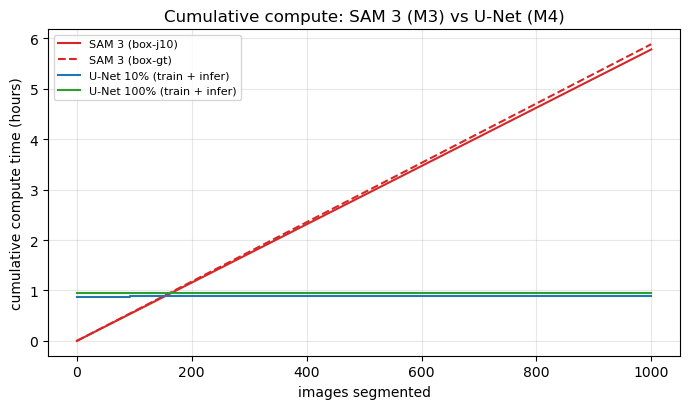

In [7]:
n = np.arange(0, 1001)
fig, ax = plt.subplots(figsize=(7, 4.2))
for s, ls in [("box-j10", "-"), ("box-gt", "--")]:
    ax.plot(n, n * sam_total_s[s] / 3600, ls, color="tab:red", label=f"SAM 3 ({s})")
for b, c in [("10pct", "tab:blue"), ("100pct", "tab:green")]:
    ax.plot(n, (unet_train_s[b] + n * unet_infer_s[b]) / 3600, color=c, label=f"U-Net {b.replace('pct', '%')} (train + infer)")
ax.set_xlabel("images segmented"); ax.set_ylabel("cumulative compute time (hours)")
ax.set_title("Cumulative compute: SAM 3 (M3) vs U-Net (M4)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "compute_amortisation.png", dpi=150)
plt.show()

## 6. Notes for the report

- **Cost structure.** SAM 3 needs no training and no labelled data, but spends about 20.8 s per image (sd 6.2 s) on the image encoder, which is 99.8 % of its per-image cost, plus 30–409 ms per prompt (box-j10 33 ms, pt-3 76 ms, box-gt 409 ms) on the MacBook Pro (M3). The U-Net, with 111x fewer parameters (7.76 M vs 860 M), trains once in about 53–57 min on the Mac mini (M4), from 10 % to 100 % of the data, and then segments an image in about 2.7 ms on average (median 2.1 ms).
- **Training time does not scale with data.** Training took 52.8, 54.6, 56.1 and 56.8 min at 10, 25, 50 and 100 %, because every bracket used the same 8,800-step budget (matched-budget design). Compute cost therefore does not fall as the training set shrinks; only annotation cost does.
- **Break-even.** Compute alone favours the U-Net after roughly 150–165 images, depending on bracket and prompt (150 for box-gt at 10 %, 164 for box-j10 at 100 %). Allowing for the hardware difference by scaling the U-Net training time by 0.5–2x moves this to about 75–330 images. At 1,000 images SAM 3 needs about 5.8 h of compute against about 0.9 h for the U-Net, including its training. Annotation cost is excluded and would add to the U-Net side.
- **Caveats.** The two arms were profiled on different machines (M3 vs M4), so `same_hardware_required` was not met and the break-even is quoted as approximate. The U-Net inference latency has a heavy tail (sd about 8 ms on a 2.7 ms mean; median 2.1 ms), likely warm-up calls, so quote the median or the mean with this note. Peak memory (U-Net about 560–630 MB, SAM 3 about 1,131 MB) is a process-level figure and cannot separate training from inference. The profile covers the 200 test images.